In [17]:
#Ok let's open the data

import pandas as pd
from pathlib import Path
PARENT_PATH_DATA = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_26_sensor_comparisons/data"


data_path_temperature = Path(PARENT_PATH_DATA)/"boston_temp_combined.csv"
data_path_pm25 = Path(PARENT_PATH_DATA)/"boston_pm25_combined.csv"


temperature_data = pd.read_csv(data_path_temperature)
pm25_data = pd.read_csv(data_path_pm25)
#Let's print the header to see what we are dealing with
print(f"Temperature columns {list(temperature_data.columns)}")
print(f"PM-2.5 columns {list(pm25_data.columns)}")

roxbury_data = pm25_data[pm25_data["site_name"] == "DUDLEY SQUARE ROXBURY"]
hillern_data = pm25_data[pm25_data["site_name"] == "VON HILLERN ST"]

Temperature columns ['date', 'year', 'month', 'mo', 'doy', 'site', 'site_name', 'lat', 'lon', 'temp_f', 'temp_max_f', 'units', 'n_obs', 'method']
PM-2.5 columns ['date', 'year', 'month', 'mo', 'doy', 'site', 'site_name', 'lat', 'lon', 'pm25', 'aqi', 'units', 'n_obs', 'method']


['BOSTON KENMORE SQ' 'Chinatown' 'DUDLEY SQUARE ROXBURY' 'VON HILLERN ST'
 'nan']
#ff79c6
Points pm25 9761
Points dates 9761
BOSTON KENMORE SQ
2024-01-25
BOSTON KENMORE SQ
2024-01-31
BOSTON KENMORE SQ
2024-03-01
BOSTON KENMORE SQ
2024-03-07
BOSTON KENMORE SQ
2024-03-19
BOSTON KENMORE SQ
2024-03-25
BOSTON KENMORE SQ
2024-03-31
BOSTON KENMORE SQ
2024-04-06
BOSTON KENMORE SQ
2024-04-12
BOSTON KENMORE SQ
2024-04-18
BOSTON KENMORE SQ
2024-04-24
BOSTON KENMORE SQ
2024-04-30
BOSTON KENMORE SQ
2024-05-06
BOSTON KENMORE SQ
2024-05-12
BOSTON KENMORE SQ
2024-05-18
BOSTON KENMORE SQ
2024-05-24
BOSTON KENMORE SQ
2024-05-30
BOSTON KENMORE SQ
2024-06-05
BOSTON KENMORE SQ
2024-06-11
BOSTON KENMORE SQ
2024-06-17
BOSTON KENMORE SQ
2024-06-23
BOSTON KENMORE SQ
2024-06-29
BOSTON KENMORE SQ
2024-07-05
BOSTON KENMORE SQ
2024-07-11
BOSTON KENMORE SQ
2024-07-17
BOSTON KENMORE SQ
2024-07-23
BOSTON KENMORE SQ
2024-07-29
BOSTON KENMORE SQ
2024-08-04
BOSTON KENMORE SQ
2024-08-10
BOSTON KENMORE SQ
2024-08-16
BOSTO

Text(0.5, 0, 'N. point')

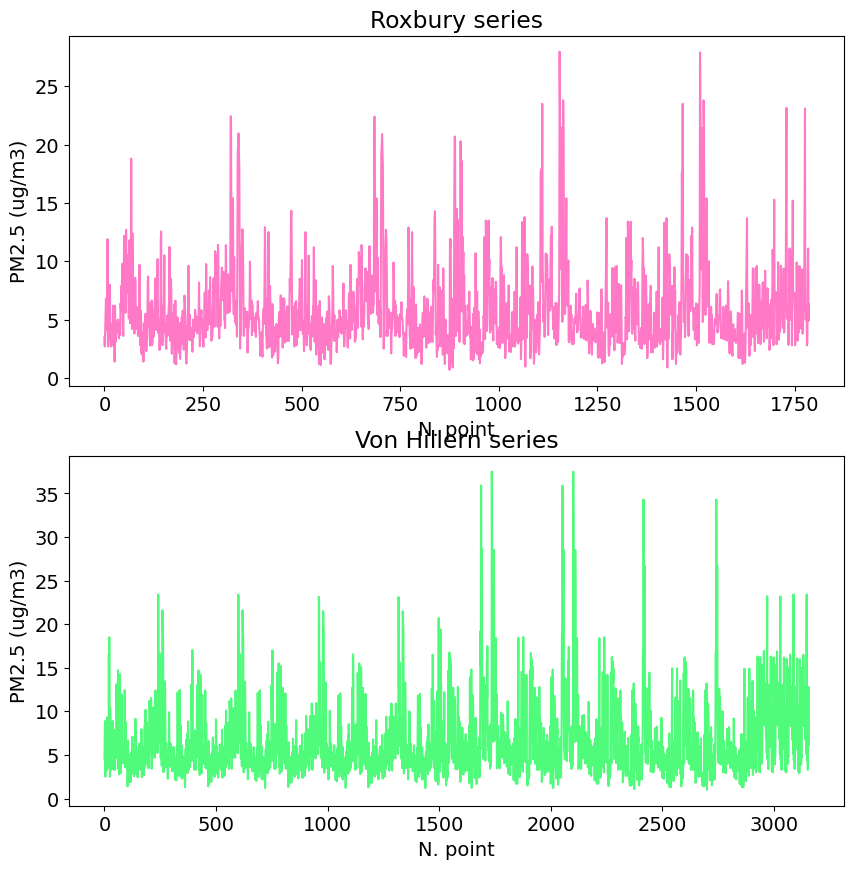

In [18]:
#Let's check the unique sites that we have
import numpy as np
from dotenv import load_dotenv

load_dotenv() 

unique_places = np.unique(list(pm25_data["site_name"]))
print(unique_places)

#OK, let's structure our analysis a little bit. 
class TimeSeriesPoint:

    def __init__(self, place, value, date):
        self.place = place
        self.value = value
        self.date = date
    
import os
PINK_DRACULA = os.environ.get('DRACULA_PINK')
GREEN_DRACULA = os.environ.get('DRACULA_GREEN')

print(PINK_DRACULA)

avg_pm25 = list(pm25_data["pm25"])
dates = list(pm25_data["date"])
places = list(pm25_data["site_name"])

print(f"Points pm25 {len(avg_pm25)}")
print(f"Points dates {len(dates)}")
time_series = []
n_points = len(avg_pm25)
for i in range(0,n_points):
    value = avg_pm25[i]
    date = dates[i]
    place = places[i]
    print(place)
    print(date)
    #Point
    point = TimeSeriesPoint(
        place = place,
        value = value,
        date = date
    )
    time_series.append(point)



roxbury_pm25_series = [x for x in time_series if x.place == "DUDLEY SQUARE ROXBURY"]
von_hillern_st_pm25_series = [x for x in time_series if x.place == "VON HILLERN ST"]


import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1, figsize = (10, 10))
ax[0].plot([x.value for x in roxbury_pm25_series], color = PINK_DRACULA)
ax[0].set_title("Roxbury series")
ax[0].set_ylabel("PM2.5 (ug/m3)")
ax[0].set_xlabel("N. point")

ax[1].plot([x.value for x in von_hillern_st_pm25_series], color = GREEN_DRACULA)
ax[1].set_title("Von Hillern series")
ax[1].set_ylabel("PM2.5 (ug/m3)")
ax[1].set_xlabel("N. point")




In [19]:
#Ok, now we'll need to import our own

DATA_PATH_SRC_OURS = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/sensors")

sensor_name_to_file = {
    "Boston Carter Field (ours)": "boston_carter_field/boston_carter_field.csv",
    "Boston Carter Field (ref)": "boston_carter_field_reference/MOD-00157-CarterField.csv",
    "Boston Robinson Hall": "boston_robinson_hall/boston_robinson_hall.csv",
    "Boston Gainsborough Parking": "boston_gainsborough_parking/boston_gainsborough_parking.csv",
    "Boston West Village B": "boston_west_village_b/boston_west_village_b.csv",
    "Boston World Series Way":"boston_world_series_way/boston_world_series_way.csv"
}

sensor_names = list(sensor_name_to_file.keys())
data_boston = {}
for i in range(0,len(sensor_names)):
    sensor_name = sensor_names[i]
    complete_file_path = DATA_PATH_SRC_OURS/sensor_name_to_file[sensor_name]
    data_boston[sensor_name] = pd.read_csv(complete_file_path)

MIN_VALID_PM25 = 0.01
MAX_VALID_PM25 = 200

for sensor_name in sensor_names:
    sensor_pm25 = pd.to_numeric(data_boston[sensor_name]["pm25"], errors = "coerce")
    is_valid = (sensor_pm25 >= MIN_VALID_PM25) & (sensor_pm25 <= MAX_VALID_PM25)
    n_low = int((sensor_pm25.notna() & (sensor_pm25 < MIN_VALID_PM25)).sum())
    n_high = int((sensor_pm25.notna() & (sensor_pm25 > MAX_VALID_PM25)).sum())
    data_boston[sensor_name]["pm25"] = sensor_pm25.where(is_valid)
    print(f"{sensor_name}: dropped {n_low} samples below {MIN_VALID_PM25} and {n_high} above {MAX_VALID_PM25} ug/m3")

roxbury_data["timestamp"] = roxbury_data["date"]
hillern_data["timestamp"] = hillern_data["date"]

import sys
sys.path.append("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/src/time_series")
from series_aligner import align_sensor_series_from_list

aligned_df, info = align_sensor_series_from_list(
    sensor_dataframes = [roxbury_data, hillern_data] + [data_boston[key] for key in sensor_names],
    variable_name = "pm25",
    time_column = "timestamp",
    sensor_names = ["Roxbury (EPA)", "Von Hillern (EPA)"] + sensor_names,
    sampling_interval = "24h",
    min_sensors=8
)



Boston Carter Field (ours): dropped 1 samples below 0.01 and 52 above 200 ug/m3
Boston Carter Field (ref): dropped 0 samples below 0.01 and 0 above 200 ug/m3
Boston Robinson Hall: dropped 26366 samples below 0.01 and 0 above 200 ug/m3
Boston Gainsborough Parking: dropped 6 samples below 0.01 and 4 above 200 ug/m3
Boston West Village B: dropped 12457 samples below 0.01 and 0 above 200 ug/m3
Boston World Series Way: dropped 84 samples below 0.01 and 7 above 200 ug/m3


array([<Axes: title={'center': 'Roxbury (EPA)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Von Hillern (EPA)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Carter Field (ours)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Carter Field (ref)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Robinson Hall'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Gainsborough Parking'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston West Village B'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston World Series Way'}, xlabel='Time', ylabel='Value'>],
      dtype=object)

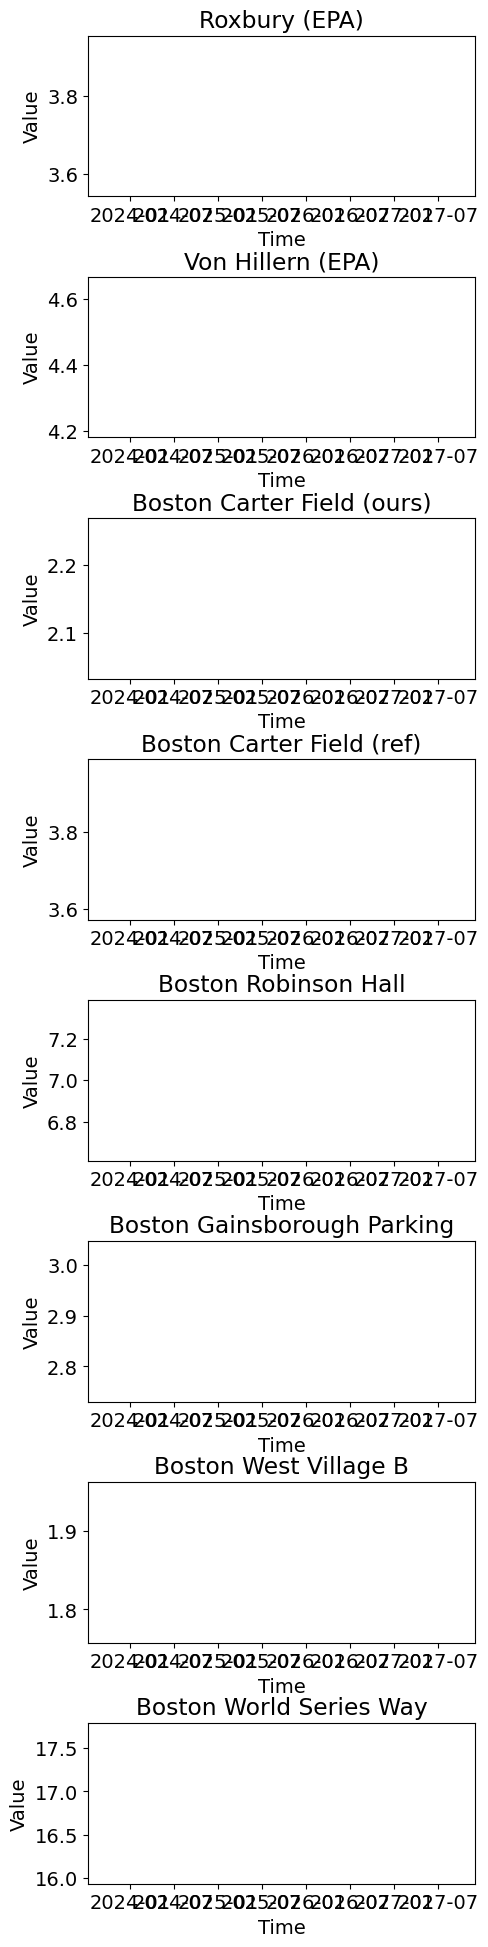

In [20]:
extended_keys = ["Roxbury (EPA)", "Von Hillern (EPA)"] + sensor_names
sys.path.append("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/src/visualization")

from time_series_plotter import TimeSeriesPlotter
from datetime import timedelta
plotter = TimeSeriesPlotter()



plotter.plot(
    list(aligned_df.index),
    time_series_data = [list(aligned_df[key]) for key in list(aligned_df.keys())],
    max_gap = timedelta(hours = 24),
    titles = extended_keys
)

In [21]:
aligned_df.head(10)

,Roxbury (EPA),Von Hillern (EPA),Boston Carter Field (ours),Boston Carter Field (ref),Boston Robinson Hall,Boston Gainsborough Parking,Boston West Village B,Boston World Series Way
timestamp,,,,,,,,
2025-09-21,3.747917,4.423958,2.151064,3.781,7.0,2.889362,1.86,16.861702


## One to one comparisons with the EPA stations

Let's get the distance to the stations. 

In [22]:
import numpy as np

DATA_PATH_SPATIAL = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/spatial/data-1775857265051.csv")
sensor_locations_data = pd.read_csv(DATA_PATH_SPATIAL)

sensor_name_to_location_name = {
    "Boston Carter Field (ours)": "Carter Field",
    "Boston Robinson Hall": "Robinson Hall",
    "Boston Gainsborough Parking": "Gainsborough Parking Garage",
    "Boston West Village B": "West Village B",
    "Boston World Series Way": "World Series Way"
}

sensor_name_to_coordinates = {}
for sensor_name in sensor_name_to_location_name:
    location_name = sensor_name_to_location_name[sensor_name]
    location_row = sensor_locations_data[sensor_locations_data["ecohub_location"].str.strip() == location_name]
    sensor_name_to_coordinates[sensor_name] = (float(location_row["lat"].iloc[0]), float(location_row["lon"].iloc[0]))

reference_sensor_data = data_boston["Boston Carter Field (ref)"]
sensor_name_to_coordinates["Boston Carter Field (ref)"] = (
    float(reference_sensor_data["lat"].dropna().iloc[0]),
    float(reference_sensor_data["lon"].dropna().iloc[0])
)

epa_station_to_coordinates = {
    "Roxbury (EPA)": (float(roxbury_data["lat"].iloc[0]), float(roxbury_data["lon"].iloc[0])),
    "Von Hillern (EPA)": (float(hillern_data["lat"].iloc[0]), float(hillern_data["lon"].iloc[0]))
}

EARTH_RADIUS_KM = 6371.0

def haversine_distance(coordinates_1, coordinates_2):
    latitude_1, longitude_1 = np.radians(coordinates_1)
    latitude_2, longitude_2 = np.radians(coordinates_2)

    delta_latitude = latitude_2 - latitude_1
    delta_longitude = longitude_2 - longitude_1

    a = np.sin(delta_latitude/2)**2 + np.cos(latitude_1)*np.cos(latitude_2)*np.sin(delta_longitude/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(a))


distance_dictionary = {}
for sensor_name in sensor_names:
    sensor_coordinates = sensor_name_to_coordinates[sensor_name]
    distance_dictionary[sensor_name] = {
        "distance_to_roxbury": haversine_distance(sensor_coordinates, epa_station_to_coordinates["Roxbury (EPA)"]),
        "distance_to_von_hillern": haversine_distance(sensor_coordinates, epa_station_to_coordinates["Von Hillern (EPA)"])
    }

for sensor_name in sensor_names:
    distance_to_roxbury = distance_dictionary[sensor_name]["distance_to_roxbury"]
    distance_to_von_hillern = distance_dictionary[sensor_name]["distance_to_von_hillern"]
    print(f"{sensor_name}: {distance_to_roxbury:.2f} km to Roxbury, {distance_to_von_hillern:.2f} km to Von Hillern")


Boston Carter Field (ours): 1.09 km to Roxbury, 2.80 km to Von Hillern
Boston Carter Field (ref): 0.99 km to Roxbury, 2.79 km to Von Hillern
Boston Robinson Hall: 1.12 km to Roxbury, 2.95 km to Von Hillern
Boston Gainsborough Parking: 1.23 km to Roxbury, 2.92 km to Von Hillern
Boston West Village B: 1.21 km to Roxbury, 3.29 km to Von Hillern
Boston World Series Way: 1.19 km to Roxbury, 3.16 km to Von Hillern


In [23]:
import matplotlib.pyplot as plt
from datetime import timedelta
from time_series_comparison_metrics import compute_rmse, compute_correlation_coefficient

epa_station_to_data = {
    "Roxbury (EPA)": roxbury_data,
    "Von Hillern (EPA)": hillern_data
}

epa_station_to_distance_key = {
    "Roxbury (EPA)": "distance_to_roxbury",
    "Von Hillern (EPA)": "distance_to_von_hillern"
}

metrics_dictionary = {}

def compare_sensor_with_epa_station(sensor_name, epa_station_name, ax):
    aligned_pair, pair_info = align_sensor_series_from_list(
        sensor_dataframes = [epa_station_to_data[epa_station_name], data_boston[sensor_name]],
        variable_name = "pm25",
        time_column = "timestamp",
        sensor_names = [epa_station_name, sensor_name],
        sampling_interval = "24h"
    )

    distance_to_station = distance_dictionary[sensor_name][epa_station_to_distance_key[epa_station_name]]

    plotter.plot(
        list(aligned_pair.index),
        time_series_data = [list(aligned_pair[epa_station_name]), list(aligned_pair[sensor_name])],
        show_in_same_plot = True,
        labels = [epa_station_name, sensor_name],
        y_labels = ["PM2.5 (ug/m3)"],
        titles = [f"{sensor_name} vs {epa_station_name} (dist = {distance_to_station:.2f} km)"],
        rotate_date_labels = True,
        max_gap = timedelta(hours = 24),
        ax = ax
    )

    station_series = list(aligned_pair[epa_station_name])
    sensor_series = list(aligned_pair[sensor_name])

    rmse = compute_rmse(station_series, sensor_series)
    coeff = compute_correlation_coefficient(station_series, sensor_series)

    print(f"{sensor_name} vs {epa_station_name}: {len(aligned_pair)} days in common, rmse = {rmse:.2f}, coeff = {coeff:.3f}")
    return {"rmse": rmse, "coeff": coeff}


def compare_sensor_with_both_stations(sensor_name):
    fig, axes = plt.subplots(1, 2, figsize = (14, 4))
    metrics_dictionary[sensor_name] = {
        "Roxbury (EPA)": compare_sensor_with_epa_station(sensor_name, "Roxbury (EPA)", axes[0]),
        "Von Hillern (EPA)": compare_sensor_with_epa_station(sensor_name, "Von Hillern (EPA)", axes[1])
    }
    fig.tight_layout()
    return metrics_dictionary[sensor_name]


### Boston Carter Field (ours)

Boston Carter Field (ours) vs Roxbury (EPA): 145 days in common, rmse = 3.05, coeff = 0.807
Boston Carter Field (ours) vs Von Hillern (EPA): 145 days in common, rmse = 3.83, coeff = 0.805


{'Roxbury (EPA)': {'rmse': np.float64(3.0527602298761654),
  'coeff': np.float64(0.8065100548028121)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.8274999297131265),
  'coeff': np.float64(0.8049793267624991)}}

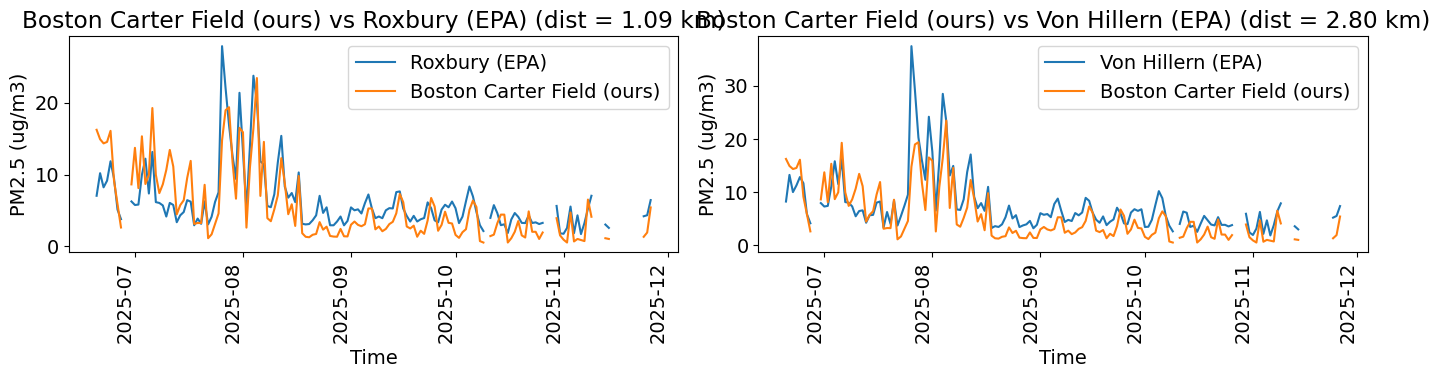

In [24]:
compare_sensor_with_both_stations("Boston Carter Field (ours)")


### Boston Carter Field (ref)

Boston Carter Field (ref) vs Roxbury (EPA): 140 days in common, rmse = 2.99, coeff = 0.801
Boston Carter Field (ref) vs Von Hillern (EPA): 140 days in common, rmse = 3.56, coeff = 0.804


{'Roxbury (EPA)': {'rmse': np.float64(2.9944858231763685),
  'coeff': np.float64(0.8014112508517557)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.556287420397512),
  'coeff': np.float64(0.8043906502750297)}}

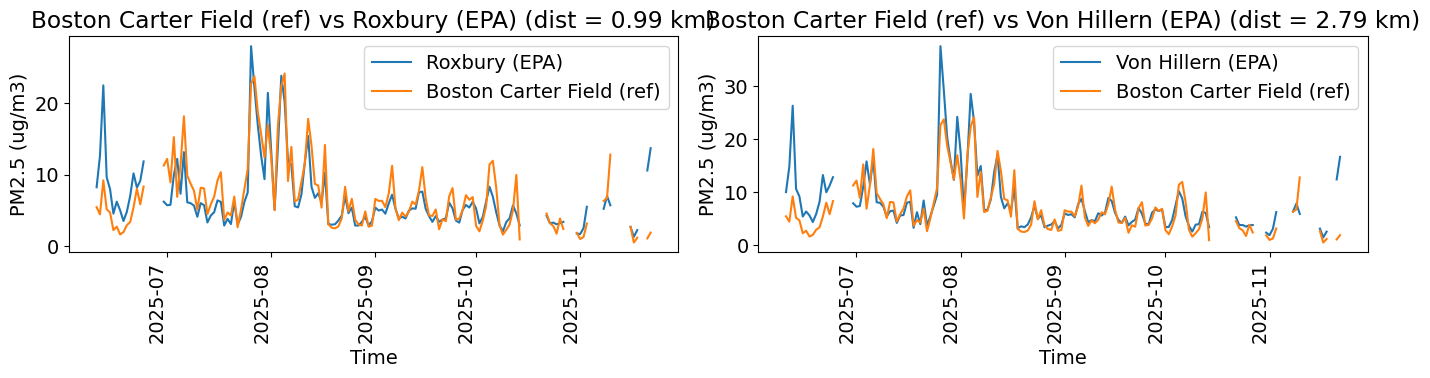

In [25]:
compare_sensor_with_both_stations("Boston Carter Field (ref)")


### Boston Robinson Hall

Boston Robinson Hall vs Roxbury (EPA): 270 days in common, rmse = 2.91, coeff = 0.803
Boston Robinson Hall vs Von Hillern (EPA): 272 days in common, rmse = 3.15, coeff = 0.830


{'Roxbury (EPA)': {'rmse': np.float64(2.9128333352974383),
  'coeff': np.float64(0.8030674151185017)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.152372120135006),
  'coeff': np.float64(0.8296159494758677)}}

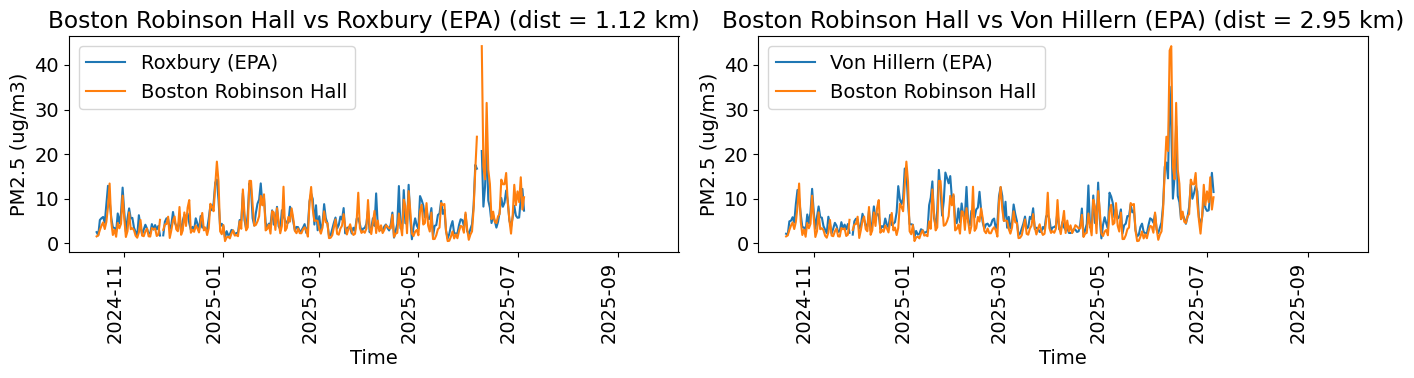

In [26]:
compare_sensor_with_both_stations("Boston Robinson Hall")


### Boston Gainsborough Parking

Boston Gainsborough Parking vs Roxbury (EPA): 370 days in common, rmse = 3.56, coeff = 0.857
Boston Gainsborough Parking vs Von Hillern (EPA): 376 days in common, rmse = 3.49, coeff = 0.859


{'Roxbury (EPA)': {'rmse': np.float64(3.5588548445293835),
  'coeff': np.float64(0.856631071116893)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.4899841945963725),
  'coeff': np.float64(0.8589926047800478)}}

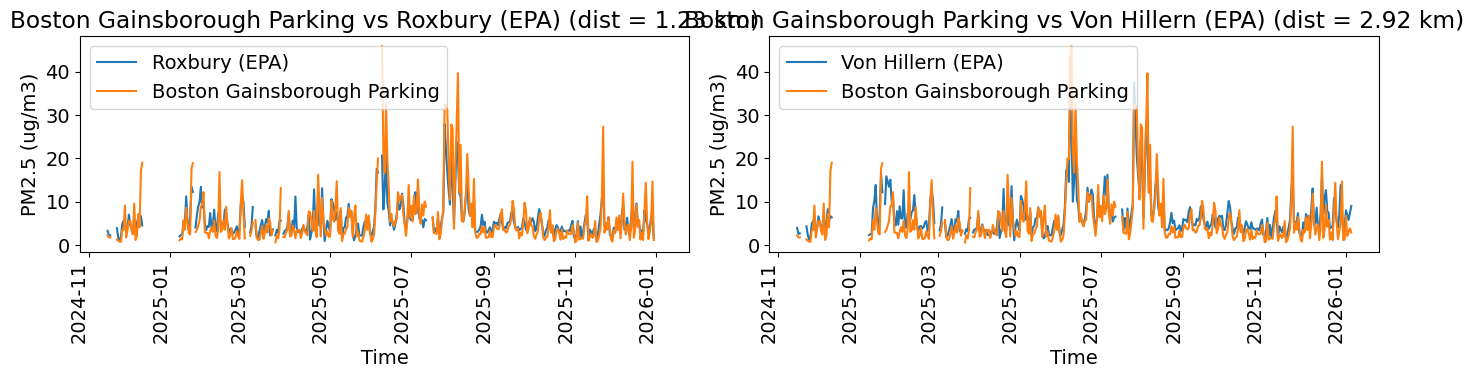

In [27]:
compare_sensor_with_both_stations("Boston Gainsborough Parking")


### Boston West Village B

Boston West Village B vs Roxbury (EPA): 221 days in common, rmse = 2.93, coeff = 0.763
Boston West Village B vs Von Hillern (EPA): 225 days in common, rmse = 3.35, coeff = 0.688


{'Roxbury (EPA)': {'rmse': np.float64(2.9279159379920077),
  'coeff': np.float64(0.7630458441715942)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.34843342303676),
  'coeff': np.float64(0.6881894414429828)}}

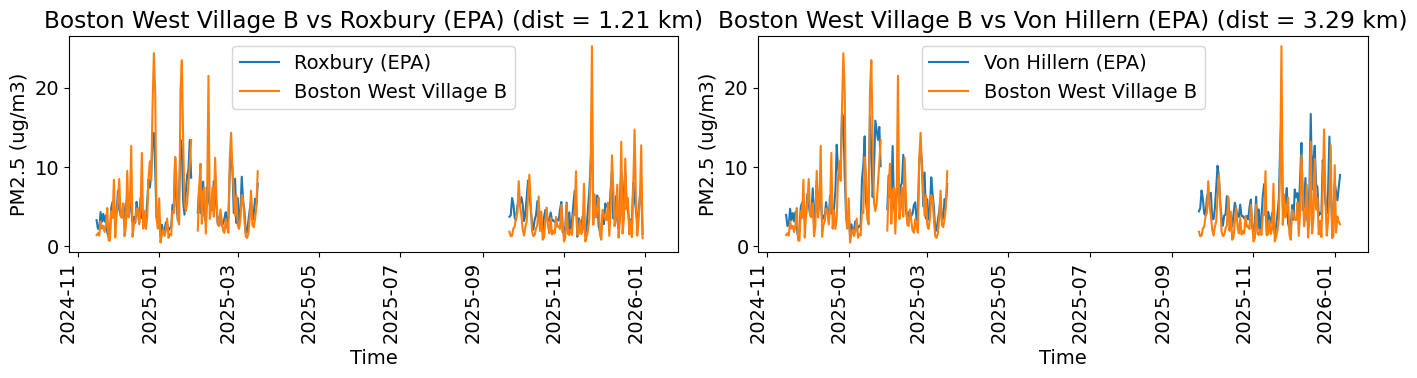

In [28]:
compare_sensor_with_both_stations("Boston West Village B")


### Boston World Series Way

Boston World Series Way vs Roxbury (EPA): 337 days in common, rmse = 5.11, coeff = 0.851
Boston World Series Way vs Von Hillern (EPA): 341 days in common, rmse = 4.57, coeff = 0.838


{'Roxbury (EPA)': {'rmse': np.float64(5.110401788916974),
  'coeff': np.float64(0.8509411776486882)},
 'Von Hillern (EPA)': {'rmse': np.float64(4.5655274564354595),
  'coeff': np.float64(0.8378844398398854)}}

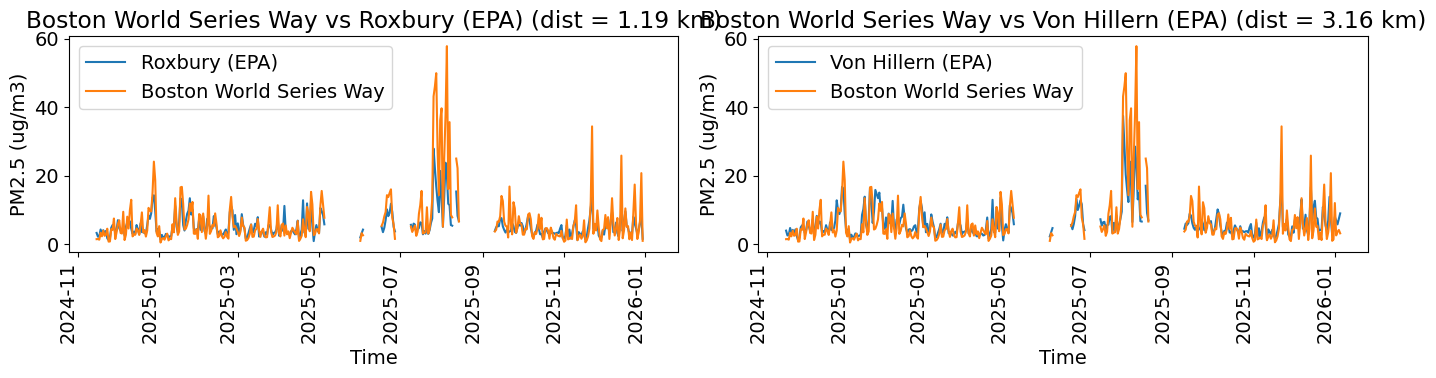

In [29]:
compare_sensor_with_both_stations("Boston World Series Way")


## RMSE and correlation against each EPA station

In [30]:
from distribution_plotter import DistributionPlotter

sensor_name_to_abbreviation = {
    "Boston Carter Field (ours)": "Carter (ours)",
    "Boston Carter Field (ref)": "Carter (ref)",
    "Boston Robinson Hall": "Robinson",
    "Boston Gainsborough Parking": "Gainsborough",
    "Boston West Village B": "West Village B",
    "Boston World Series Way": "World Series"
}

distribution_plotter = DistributionPlotter()
sensor_abbreviations = [sensor_name_to_abbreviation[sensor_name] for sensor_name in sensor_names]

def plot_metric_for_both_stations(metric_name, variable_name, title, decimals = 2, delta = 0.05, ylims = None, distance_between_values = 0.2):
    distributions = [
        {
            "x": sensor_abbreviations,
            "y": [metrics_dictionary[sensor_name]["Roxbury (EPA)"][metric_name] for sensor_name in sensor_names],
            "color_bars": PINK_DRACULA,
            "label": "Roxbury (EPA)"
        },
        {
            "x": sensor_abbreviations,
            "y": [metrics_dictionary[sensor_name]["Von Hillern (EPA)"][metric_name] for sensor_name in sensor_names],
            "color_bars": GREEN_DRACULA,
            "label": "Von Hillern (EPA)"
        }
    ]

    return distribution_plotter.multi_distribution_plotter(
        distributions,
        width = 16,
        height = 5,
        variable_name = variable_name,
        title = title,
        values_on_top = True,
        decimals = decimals,
        delta = delta,
        ylims = ylims,
        distance_between_values = distance_between_values
    )


<Axes: title={'center': 'RMSE of each sensor against the EPA stations'}, ylabel='RMSE (ug/m3)'>

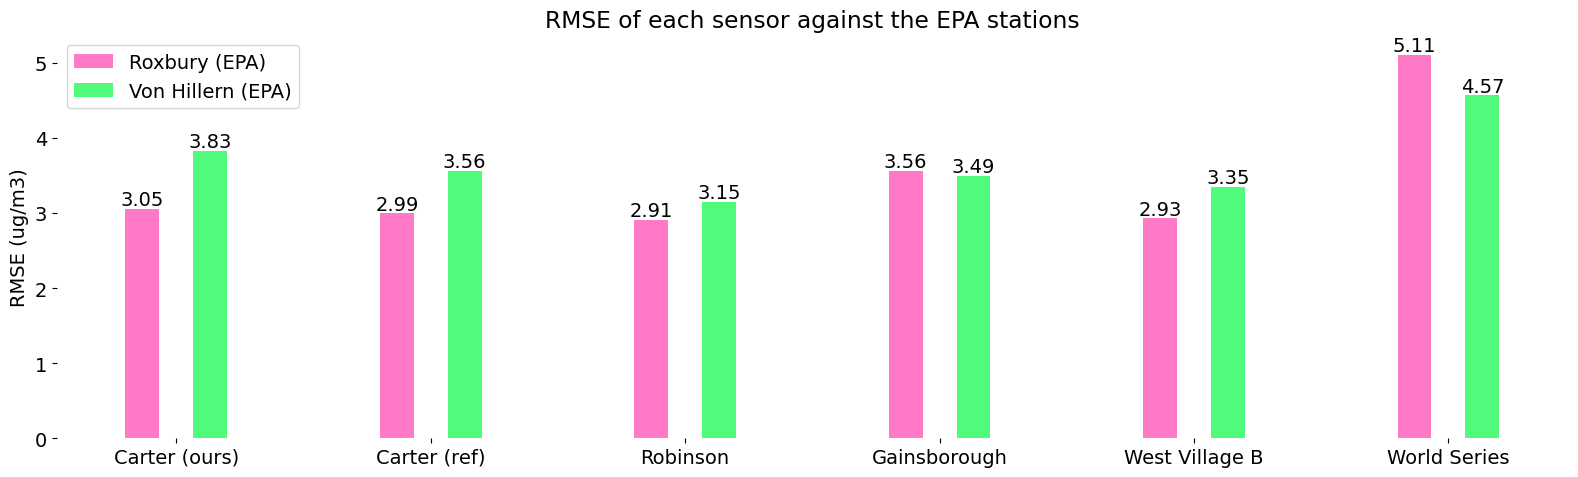

In [31]:
plot_metric_for_both_stations(
    "rmse",
    variable_name = "RMSE (ug/m3)",
    title = "RMSE of each sensor against the EPA stations",
    decimals = 2,
    delta = 0.05
)


<Axes: title={'center': 'Correlation of each sensor with the EPA stations'}, ylabel='Correlation coefficient'>

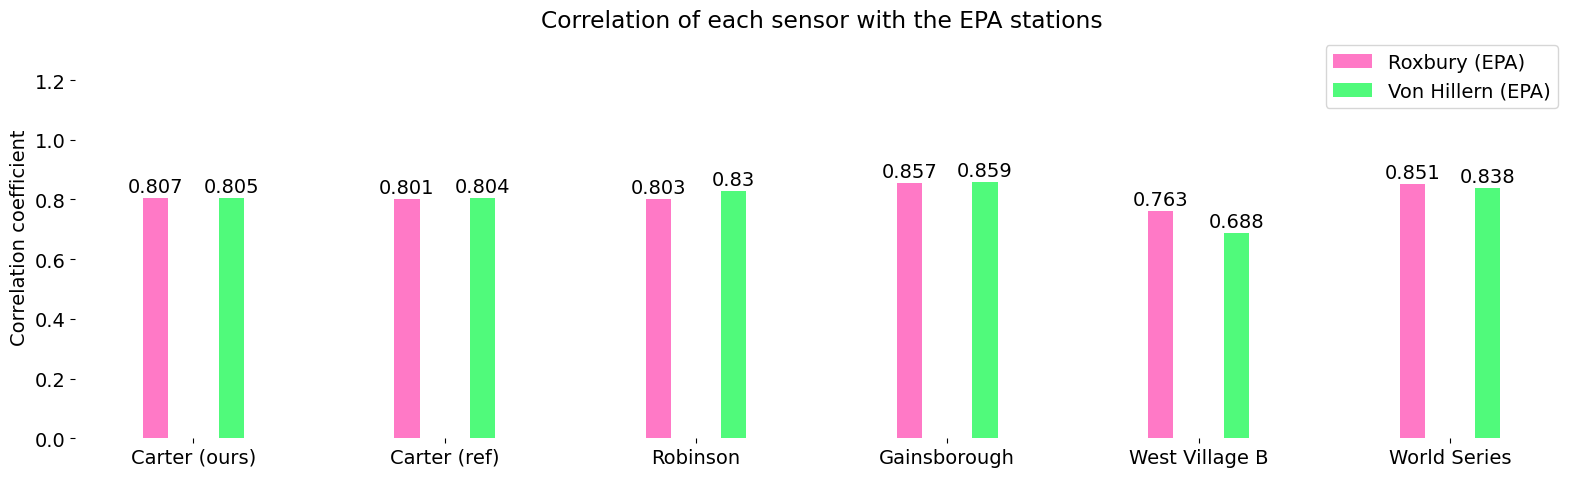

In [32]:
plot_metric_for_both_stations(
    "coeff",
    variable_name = "Correlation coefficient",
    title = "Correlation of each sensor with the EPA stations",
    decimals = 3,
    delta = 0.02,
    ylims = [0, 1.35],
    distance_between_values = 0.4
)
